# 5. Single events

A planet with a period longer than half the data makes one transit, or none. A
period search cannot find it. The tool `single_events` scores a box of each width
at each time and returns the strongest dips that do not repeat. This notebook
injects one transit into the loaded episode and shows the statistic.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


## One injected transit

The injection has a 45-day period and an epoch at day 25, so one transit lies in
the data, away from the gaps. The plot marks it. The host already has the
periodic signal of the episode, so the single transit must stand out beside it.

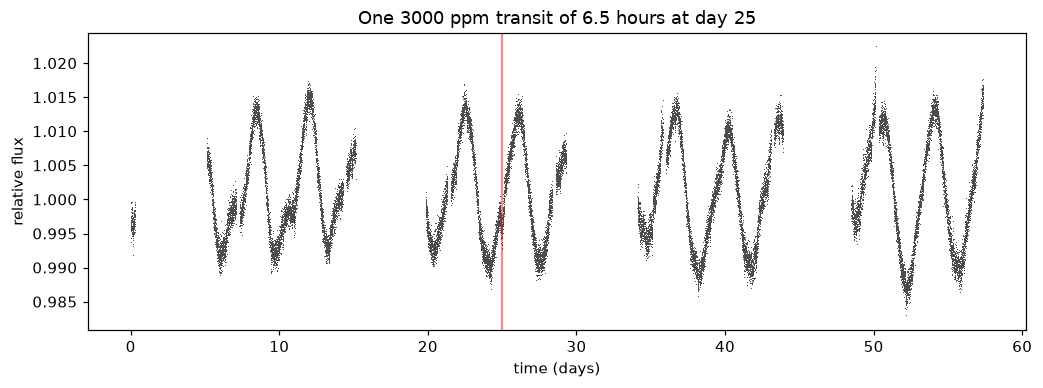

In [2]:
from stargazer.inject import inject, make_truth

star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
lone = make_truth(period=45.0, t0=25.0, depth=0.003, b=0.2, star=star)
with_event = inject(time, flux, lone)
fig, axis = plt.subplots()
axis.plot(time, with_event, ",", color="0.3")
axis.axvline(25.0, color="tab:red", alpha=0.5)
axis.set_xlabel("time (days)")
axis.set_ylabel("relative flux")
axis.set_title(f"One {lone.depth * 1e6:.0f} ppm transit of {lone.duration * 24:.1f} hours at day 25")
plt.show()

## The single-event statistic

For a box of width $d$ the statistic is

$$\mathrm{snr} = \frac{\bar{f}_\mathrm{median} - \bar{f}_\mathrm{box}}{\sigma_d}$$

where $\bar{f}_\mathrm{box}$ is the mean flux in the box and $\sigma_d$ is the noise
at the box timescale, 1.4826 times the median absolute deviation of the box means
over the whole light curve. On white noise it equals the point scatter over the
square root of the points in the box. On an active star it is larger, so slow
variability does not produce an event with a high statistic. Each box width is
detrended with a window of at least six widths, so a short window cannot erase a
long event. A box near the start or the end of a data segment is skipped, because
the detrending filter leaves a dip-shaped residual there.

In [3]:
from stargazer.tools import single_events

events = single_events(time, with_event)
for event in events["events"]:
    print(event)

{'time': 24.9907, 'duration': 0.04, 'depth_ppm': 3156.9, 'snr': 9.1, 'noise_ppm': 347.1, 'n_points': 29}
{'time': 9.4912, 'duration': 0.5, 'depth_ppm': 3729.8, 'snr': 2.0, 'noise_ppm': 1867.0, 'n_points': 360}


/home/siddharth899/personal_code/star_finder/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## The strongest event

The plot zooms on the strongest event in the detrended flux, with the window the
tool used for that box width. A transit-like event has a duration of hours, a flat
curve on each side, and no partner of the same depth elsewhere. A lone event that
passes those checks is submitted as a single event: a time, a duration and a depth,
and no period.

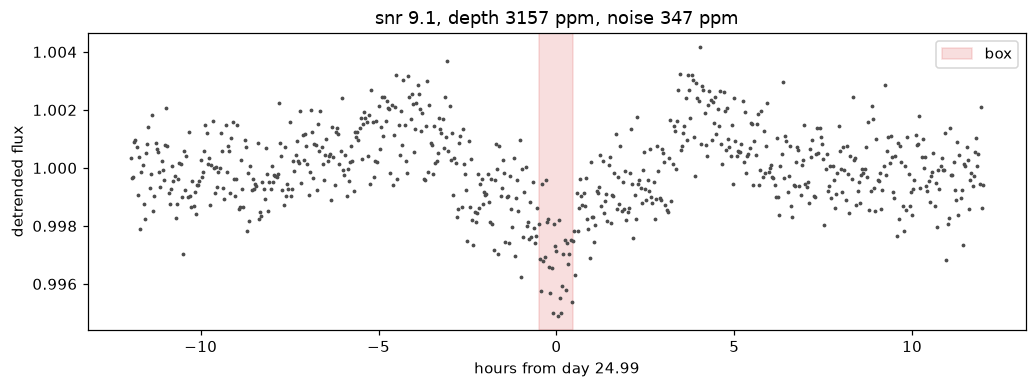

In [4]:
from stargazer.baseline import detrend

top = events["events"][0]
flat_time, flat_flux = detrend(time, with_event, max(0.75, 6.0 * top["duration"]))
near = np.abs(flat_time - top["time"]) < 0.5
fig, axis = plt.subplots()
axis.plot((flat_time[near] - top["time"]) * 24, flat_flux[near], ".", ms=3, color="0.3")
axis.axvspan(-top["duration"] * 12, top["duration"] * 12, color="tab:red", alpha=0.15, label="box")
axis.set_xlabel(f"hours from day {top['time']:.2f}")
axis.set_ylabel("detrended flux")
axis.set_title(f"snr {top['snr']}, depth {top['depth_ppm']:.0f} ppm, noise {top['noise_ppm']:.0f} ppm")
axis.legend()
plt.show()